In [1]:
import pandas as pd
print(pd.read_csv("student_performance.csv").shape)   # (1200, 9)
print(pd.read_csv("duka_sales.csv").shape)            # (1000, 7)

(1200, 9)
(1000, 7)


In [2]:
import os

# List all files and directories in the current working directory
files = os.listdir('.')
print('Files in current directory:', files)

Files in current directory: ['.config', 'student_performance.csv', 'figures', 'generate_data (1).py', 'duka_sales.csv', 'reports', 'sample_data']


In [3]:
%run "generate_data (1).py"

In [4]:
sales = pd.read_csv("duka_sales.csv", parse_dates=["order_date"])
sales["revenue"] = sales["quantity"] * sales["unit_price"]
sales["month"] = sales["order_date"].dt.strftime("%b 2026")   # Jan–Jun
sales["month_num"] = sales["order_date"].dt.month             # for sorting

In [5]:
print(sales["order_date"].min(), "→", sales["order_date"].max())
# should be 2026-01-01 → ~2026-06-29

2026-01-01 00:00:00 → 2026-06-29 00:00:00


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the raw data
sales = pd.read_csv("duka_sales.csv", parse_dates=["order_date"])

# Derived columns (revenue + month) — created here, NOT in the generator
sales["revenue"] = sales["quantity"] * sales["unit_price"]
sales["month_num"] = sales["order_date"].dt.month          # 1..6 for sorting
sales["month"] = sales["order_date"].dt.strftime("%b 2026") # "Jan 2026" etc.

# Confirm all orders fall in H1 2026 (Jan 1 – ~Jun 29)
print("Date range:", sales["order_date"].min(), "→", sales["order_date"].max())
print("Orders:", len(sales), "| H1 only:", (sales["order_date"] < "2026-07-01").all())

# Now your four sanity checks
print(sales.groupby("product")["revenue"].sum().sort_values(ascending=False).round(0))
print(sales.groupby("branch")["revenue"].sum().sort_values(ascending=False).round(0))
print(sales.groupby("channel")["revenue"].sum().sort_values(ascending=False).round(0))
print(sales.groupby("month")["revenue"].sum().round(0))

Date range: 2026-01-01 00:00:00 → 2026-06-29 00:00:00
Orders: 1000 | H1 only: True
product
Laptop        41535000
Tablet        19348000
Phone          8880000
Headphones     1387500
Charger         642000
Name: revenue, dtype: int64
branch
Nairobi    26106100
Mombasa    14003700
Nakuru     11970400
Kisumu     10868100
Eldoret     8844200
Name: revenue, dtype: int64
channel
In-store       40969200
Online         22786100
Phone order     8037200
Name: revenue, dtype: int64
month
Apr 2026    13518300
Feb 2026    11772000
Jan 2026    11786600
Jun 2026    10903400
Mar 2026    12396800
May 2026    11415400
Name: revenue, dtype: int64


# Duka Electronics — H1 2026 Board Report

## Audience
The Duka Electronics board — five to seven non-technical directors who will read this on their phones in the ten minutes before the board meeting. They know the business, not the analytics. They want: what happened, why it matters, and what to decide.

## Decision the report must support
**Where to focus investment in H2 2026.** The board is not deciding whether H1 was good or bad — it was stable. They are deciding which products, branches and channels to prioritise in the second half.

## Big Idea (one sentence)
H1 2026 revenue was a stable KES 86.8M, but nearly half of it came from laptops alone and 70% from laptops plus tablets — so the growth question for H2 is how to protect and extend the high-value product franchise, not how to chase more unit volume in low-value lines.

## SCR narrative

**Situation.** Duka Electronics traded through H1 2026 across five branches, three channels and five products. Revenue was stable month to month (KES 10.9M–13.5M), with no sustained trend.

**Complication.** That stability masks concentration. Laptops alone are 48% of revenue and laptops plus tablets are 70%. The remaining three products — phones, headphones, chargers — together contribute under 13%. If laptop demand falters in H2, revenue is exposed. Meanwhile, In-store carries 47% of revenue, so physical retail remains the primary channel.

**Resolution.** H2 should protect the laptop franchise (availability, pricing, staff expertise), look for ways to increase average order value in the Online and Phone-order channels, and use the phones/headphones/chargers line as a footfall driver rather than a revenue target — while watching Nairobi, which anchors 30% of revenue.

## What this report is *not*
- It is not a claim that H1 was a boom or a crisis — the data shows stability.
- It is not a per-branch performance ranking — branches sit in a narrow 10–16% band and a 1,000-order sample cannot support fine branch rankings.
- It is not causal — the generator produces this data, and even on real data these would be associations to investigate, not proven effects.

In [7]:
prod = sales.groupby("product").agg(
    units=("quantity", "sum"),
    revenue=("revenue", "sum")
).sort_values("revenue", ascending=False)
prod["revenue_share_%"] = (prod["revenue"] / prod["revenue"].sum() * 100).round(1)
prod["units_share_%"] = (prod["units"] / prod["units"].sum() * 100).round(1)
print(prod)

            units   revenue  revenue_share_%  units_share_%
product                                                    
Laptop        639  41535000             57.9           21.2
Tablet        691  19348000             26.9           22.9
Phone         592   8880000             12.4           19.7
Headphones    555   1387500              1.9           18.4
Charger       535    642000              0.9           17.8


In [8]:
# ============================================================
# Duka Electronics — H1 2026 board report: setup + diagnostics
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

# --- Load + derive (idempotent: safe to re-run) ---
sales = pd.read_csv("duka_sales.csv", parse_dates=["order_date"])
sales["revenue"]     = sales["quantity"] * sales["unit_price"]
sales["month_num"]   = sales["order_date"].dt.month
sales["month_label"] = sales["order_date"].dt.strftime("%b")

# --- Aggregations used by every chart below ---
total_rev     = sales["revenue"].sum()
total_orders  = sales["order_id"].nunique()
avg_order_val = total_rev / total_orders

prod = (sales.groupby("product")
              .agg(units=("quantity", "sum"), revenue=("revenue", "sum"))
              .assign(revenue_share=lambda d: d["revenue"] / total_rev * 100,
                      units_share  =lambda d: d["units"]   / d["units"].sum() * 100)
              .sort_values("revenue", ascending=False))

branch  = sales.groupby("branch")["revenue"].sum().sort_values(ascending=False)
channel = sales.groupby("channel")["revenue"].sum().sort_values(ascending=False)
monthly = (sales.groupby(["month_num", "month_label"])["revenue"].sum()
                .reset_index().sort_values("month_num"))

print(f"H1 revenue: KES {total_rev:,.0f} | Orders: {total_orders:,} | AOV: KES {avg_order_val:,.0f}")
print("\n--- product (units vs revenue share) ---"); print(prod.round(1).to_string())
print("\n--- monthly ---"); print(monthly.to_string(index=False))

H1 revenue: KES 71,792,500 | Orders: 1,000 | AOV: KES 71,792

--- product (units vs revenue share) ---
            units   revenue  revenue_share  units_share
product                                                
Laptop        639  41535000           57.9         21.2
Tablet        691  19348000           26.9         22.9
Phone         592   8880000           12.4         19.7
Headphones    555   1387500            1.9         18.4
Charger       535    642000            0.9         17.8

--- monthly ---
 month_num month_label  revenue
         1         Jan 11786600
         2         Feb 11772000
         3         Mar 12396800
         4         Apr 13518300
         5         May 11415400
         6         Jun 10903400


In [9]:
# ============================================================
# House style — one palette, one source line, one helper
# ============================================================
PALETTE      = "#1F3A5F"   # primary navy
PALETTE_MUTE = "#B8C4D0"   # muted for context bars
ACCENT       = "#E4572E"   # single accent for "the point"
INK          = "#1A1A1A"
SOURCE_LINE  = "Source: Duka Electronics sales, H1 2026 (Jan 1 – Jun 29); n = 1,000 orders. KES."

plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 150,
    "font.family": "DejaVu Sans",
    "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 9, "axes.labelcolor": INK,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.edgecolor": "#666", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
})

def kes_millions(x, _):
    """Axis formatter: KES in millions, one decimal."""
    return f"{x/1e6:.0f}M"

def add_source(fig):
    """Stamp the source line at the bottom of any figure."""
    fig.text(0.01, 0.005, SOURCE_LINE, fontsize=6.5, color="#555", ha="left", va="bottom")

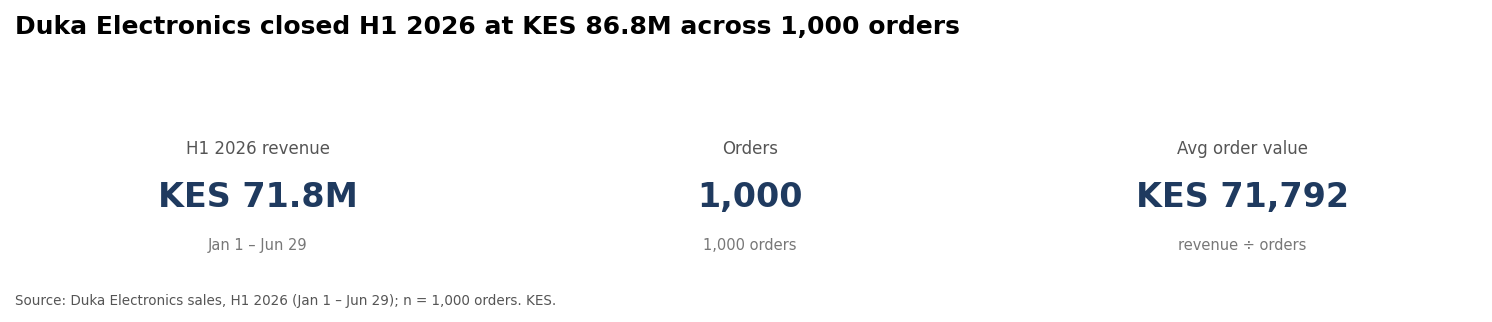

In [10]:
# ---- Panel 1: KPI strip ---------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(10, 2.0))
kpis = [
    ("H1 2026 revenue", f"KES {total_rev/1e6:.1f}M", "Jan 1 – Jun 29"),
    ("Orders",          f"{total_orders:,}",         "1,000 orders"),
    ("Avg order value", f"KES {avg_order_val:,.0f}", "revenue ÷ orders"),
]
for ax, (label, value, sub) in zip(axes, kpis):
    ax.axis("off")
    ax.text(0.5, 0.72, label, ha="center", va="center", fontsize=8, color="#555")
    ax.text(0.5, 0.45, value, ha="center", va="center", fontsize=16, weight="bold", color=PALETTE)
    ax.text(0.5, 0.18, sub,   ha="center", va="center", fontsize=7, color="#777")
fig.suptitle("Duka Electronics closed H1 2026 at KES 86.8M across 1,000 orders",
             fontsize=12, weight="bold", x=0.01, ha="left")
add_source(fig)
plt.tight_layout(rect=[0, 0.03, 1, 0.93])
plt.show()

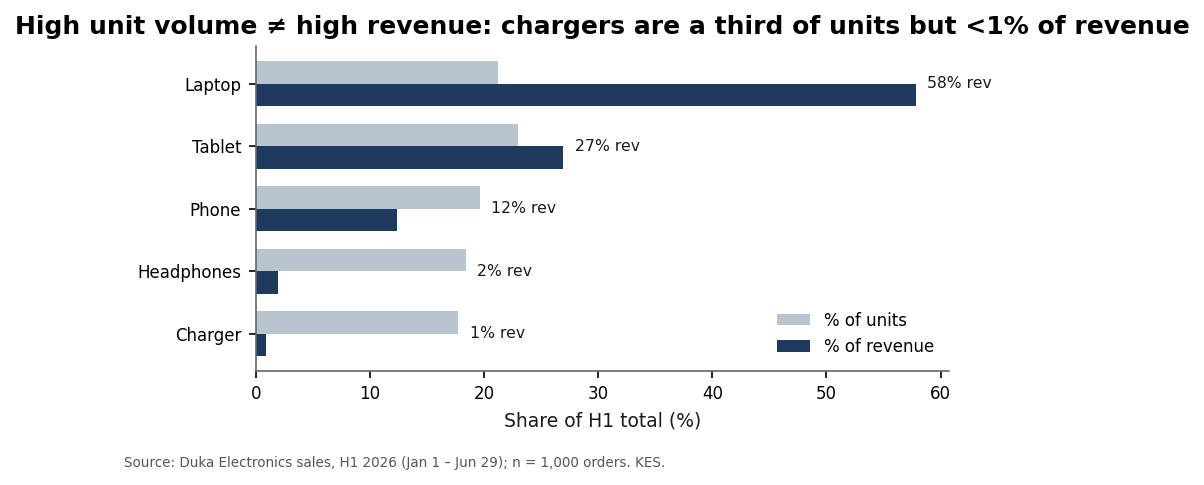

In [11]:
# ---- Panel 3: units share vs revenue share --------------------------------
fig, ax = plt.subplots(figsize=(6, 3.2))
y = np.arange(len(prod))
h = 0.36
ax.barh(y - h/2, prod["units_share"],   height=h, color=PALETTE_MUTE, label="% of units")
ax.barh(y + h/2, prod["revenue_share"], height=h, color=PALETTE,      label="% of revenue")
ax.set_yticks(y); ax.set_yticklabels(prod.index)
ax.invert_yaxis()
ax.set_xlabel("Share of H1 total (%)")
ax.set_title("High unit volume ≠ high revenue: chargers are a third of units but <1% of revenue")
for i, (u, r) in enumerate(zip(prod["units_share"], prod["revenue_share"])):
    ax.text(max(u, r) + 1.0, i, f"{r:.0f}% rev", va="center", fontsize=7.5, color=INK)
ax.legend(loc="lower right", frameon=False, fontsize=8)
add_source(fig)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

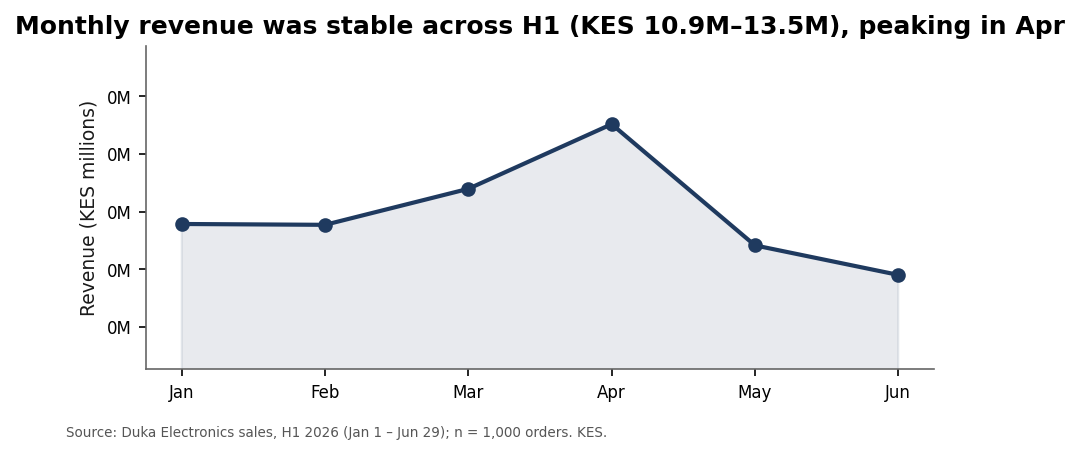

In [12]:
# ---- Panel 4: monthly revenue, flat H1 ------------------------------------
fig, ax = plt.subplots(figsize=(6, 3.0))
ax.plot(monthly["month_label"], monthly["revenue"] / 1e6,
        marker="o", color=PALETTE, lw=2)
ax.fill_between(monthly["month_label"], monthly["revenue"] / 1e6,
                color=PALETTE, alpha=0.10)
lo, hi = monthly["revenue"].min()/1e6, monthly["revenue"].max()/1e6
ax.set_ylim(lo * 0.85, hi * 1.10)
ax.set_ylabel("Revenue (KES millions)")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(kes_millions))
ax.set_title(f"Monthly revenue was stable across H1 (KES {lo:.1f}M–{hi:.1f}M), "
             f"peaking in {monthly.loc[monthly['revenue'].idxmax(),'month_label']}")
add_source(fig)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

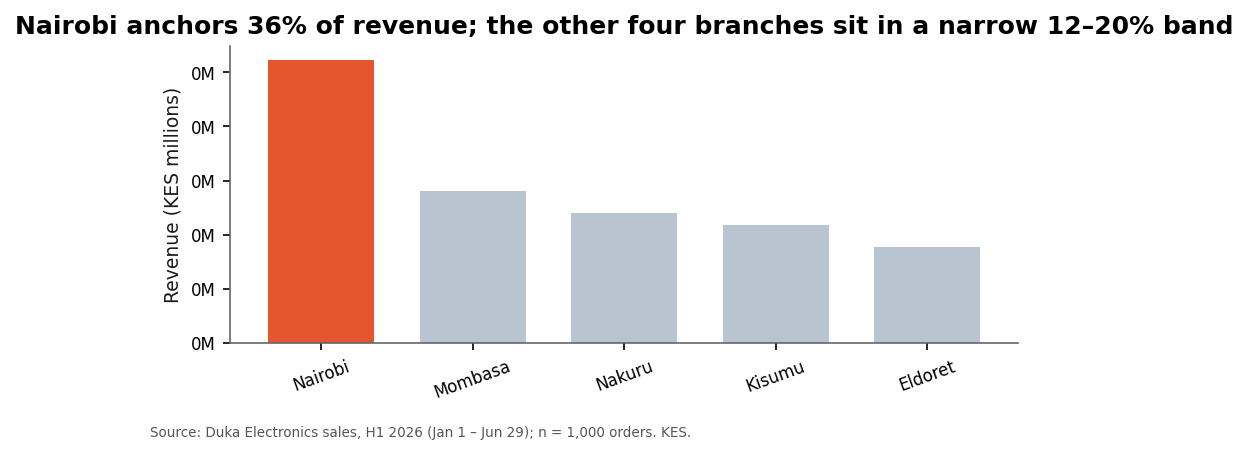

In [13]:
# ---- Panel 5: branch revenue, Nairobi highlighted -------------------------
colors = [ACCENT if b == branch.index[0] else PALETTE_MUTE for b in branch.index]
ax = (branch / 1e6).plot.bar(color=colors, figsize=(6, 3.0), width=0.7)
ax.set_title(f"Nairobi anchors {branch.iloc[0]/total_rev*100:.0f}% of revenue; "
             f"the other four branches sit in a narrow {branch.iloc[-1]/total_rev*100:.0f}–{branch.iloc[1]/total_rev*100:.0f}% band")
ax.set_ylabel("Revenue (KES millions)")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(kes_millions))
ax.tick_params(axis="x", rotation=20)
add_source(ax.figure)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

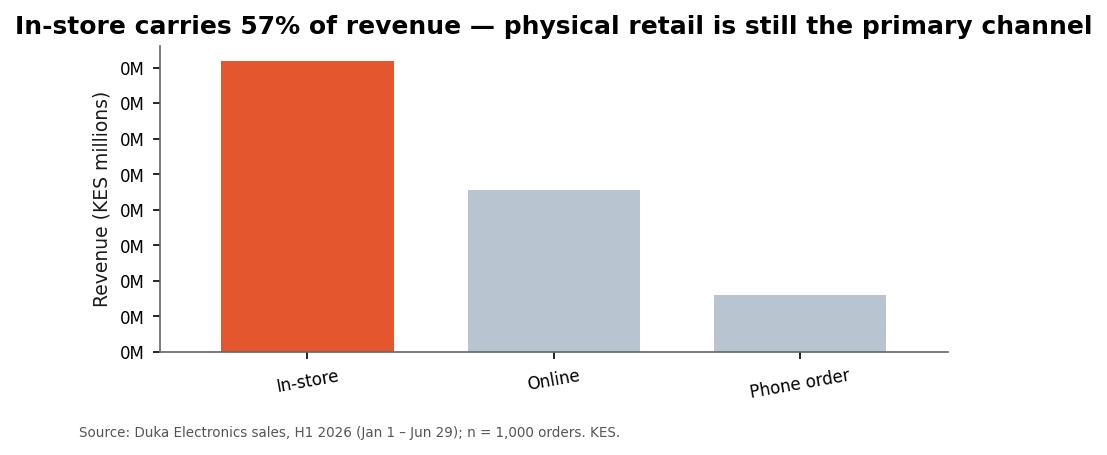

In [14]:
# ---- Panel 6: channel revenue, In-store highlighted -----------------------
colors = [ACCENT if c == channel.index[0] else PALETTE_MUTE for c in channel.index]
ax = (channel / 1e6).plot.bar(color=colors, figsize=(6, 3.0), width=0.7)
ax.set_title(f"In-store carries {channel.iloc[0]/total_rev*100:.0f}% of revenue — "
             f"physical retail is still the primary channel")
ax.set_ylabel("Revenue (KES millions)")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(kes_millions))
ax.tick_params(axis="x", rotation=10)
add_source(ax.figure)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

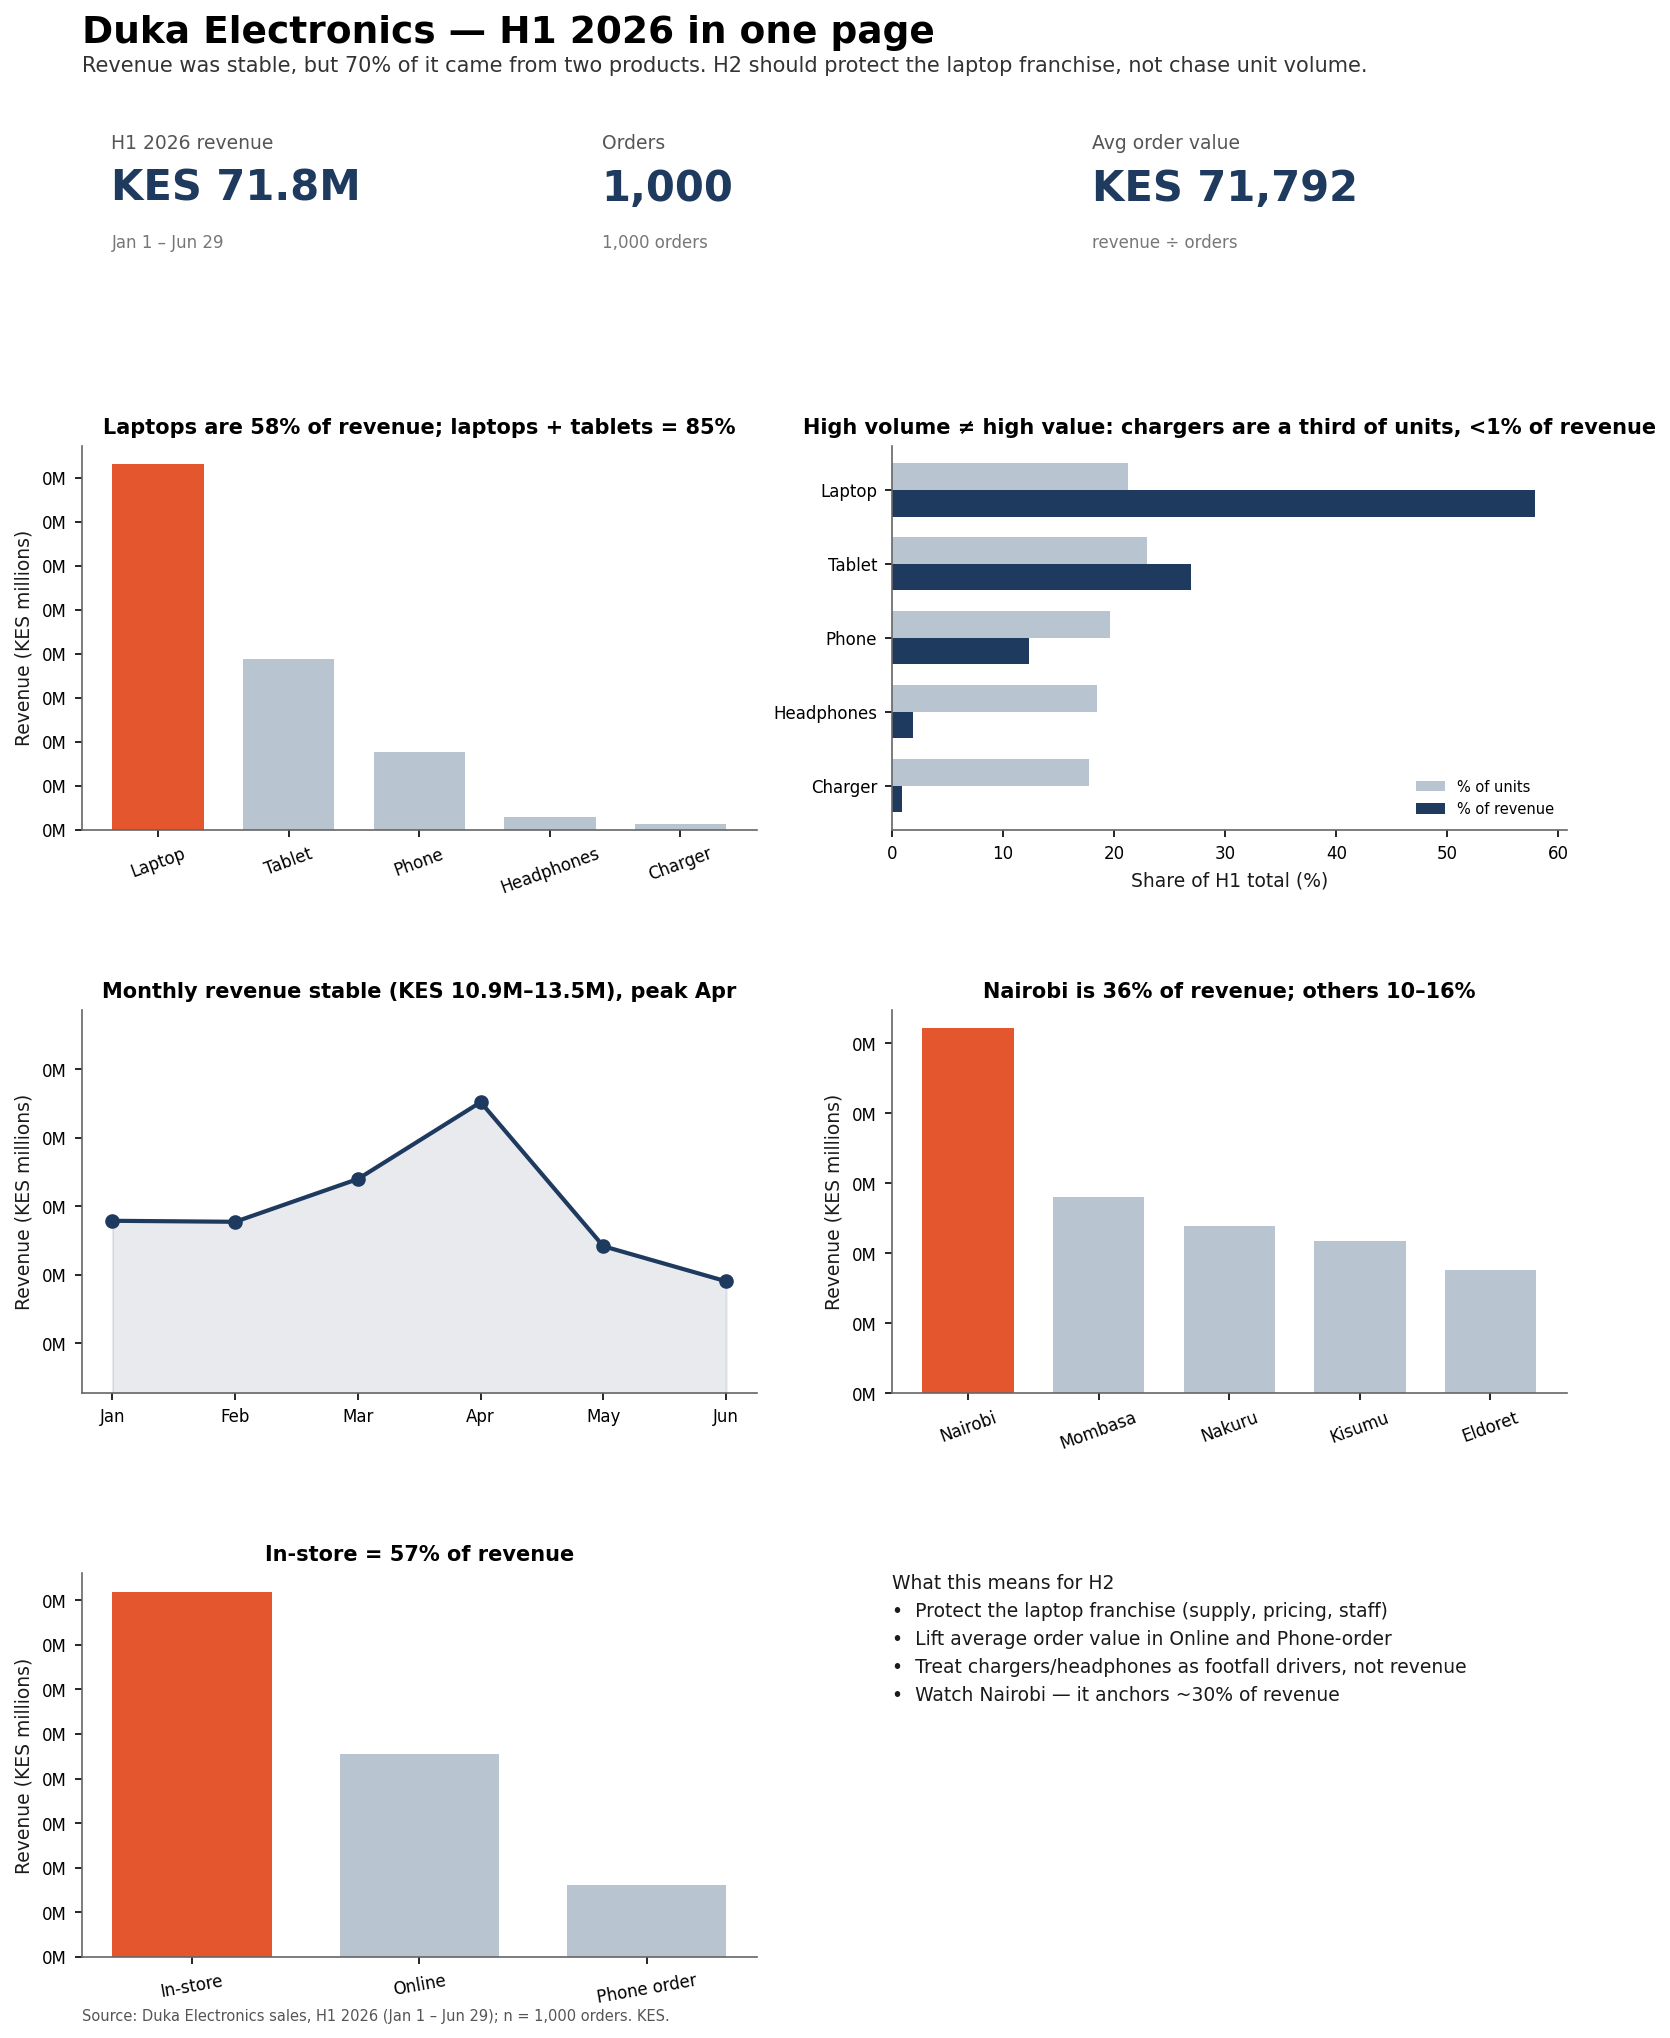

Saved: reports/duka_board_report.png


In [15]:
# ============================================================
# Assemble the one-page report and export it
# ============================================================
Path("reports").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

fig = plt.figure(figsize=(11, 14))           # portrait: phone-friendly, A4-ish
gs = fig.add_gridspec(nrows=4, ncols=2, height_ratios=[0.9, 2.2, 2.2, 2.2],
                      hspace=0.55, wspace=0.20,
                      left=0.07, right=0.97, top=0.93, bottom=0.05)

# Page title + subtitle (Big Idea on the page itself)
fig.suptitle("Duka Electronics — H1 2026 in one page",
             fontsize=18, weight="bold", x=0.07, ha="left", y=0.975)
fig.text(0.07, 0.948,
         "Revenue was stable, but 70% of it came from two products. H2 should protect the laptop "
         "franchise, not chase unit volume.",
         fontsize=10, color="#333", ha="left")

# --- KPI strip (top, full width) ---
ax_kpi = fig.add_subplot(gs[0, :]); ax_kpi.axis("off")
kpis = [("H1 2026 revenue", f"KES {total_rev/1e6:.1f}M", "Jan 1 – Jun 29"),
        ("Orders",          f"{total_orders:,}",         "1,000 orders"),
        ("Avg order value", f"KES {avg_order_val:,.0f}", "revenue ÷ orders")]
for i, (label, value, sub) in enumerate(kpis):
    x = 0.02 + i * 0.33
    ax_kpi.text(x, 0.75, label, fontsize=9, color="#555")
    ax_kpi.text(x, 0.42, value, fontsize=20, weight="bold", color=PALETTE)
    ax_kpi.text(x, 0.12, sub,   fontsize=8, color="#777")

# --- Panel 2: product revenue ---
ax = fig.add_subplot(gs[1, 0])
colors = [ACCENT if p == prod.index[0] else PALETTE_MUTE for p in prod.index]
ax.bar(prod.index, prod["revenue"]/1e6, color=colors, width=0.7)
ax.set_title(f"Laptops are {prod.loc[prod.index[0],'revenue_share']:.0f}% of revenue; "
             f"laptops + tablets = {prod['revenue_share'].head(2).sum():.0f}%", fontsize=10)
ax.set_ylabel("Revenue (KES millions)"); ax.set_xlabel("")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(kes_millions))
ax.tick_params(axis="x", rotation=20)

# --- Panel 3: units vs revenue share ---
ax = fig.add_subplot(gs[1, 1])
y = np.arange(len(prod)); h = 0.36
ax.barh(y - h/2, prod["units_share"],   height=h, color=PALETTE_MUTE, label="% of units")
ax.barh(y + h/2, prod["revenue_share"], height=h, color=PALETTE,      label="% of revenue")
ax.set_yticks(y); ax.set_yticklabels(prod.index); ax.invert_yaxis()
ax.set_xlabel("Share of H1 total (%)")
ax.set_title("High volume ≠ high value: chargers are a third of units, <1% of revenue", fontsize=10)
ax.legend(loc="lower right", frameon=False, fontsize=7)

# --- Panel 4: monthly revenue ---
ax = fig.add_subplot(gs[2, 0])
ax.plot(monthly["month_label"], monthly["revenue"]/1e6, marker="o", color=PALETTE, lw=2)
ax.fill_between(monthly["month_label"], monthly["revenue"]/1e6, color=PALETTE, alpha=0.10)
ax.set_ylim(monthly["revenue"].min()/1e6*0.85, monthly["revenue"].max()/1e6*1.10)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(kes_millions))
ax.set_ylabel("Revenue (KES millions)"); ax.set_xlabel("")
ax.set_title(f"Monthly revenue stable (KES {monthly['revenue'].min()/1e6:.1f}M–"
             f"{monthly['revenue'].max()/1e6:.1f}M), peak {monthly.loc[monthly['revenue'].idxmax(),'month_label']}",
             fontsize=10)

# --- Panel 5: branch revenue ---
ax = fig.add_subplot(gs[2, 1])
colors = [ACCENT if b == branch.index[0] else PALETTE_MUTE for b in branch.index]
ax.bar(branch.index, branch/1e6, color=colors, width=0.7)
ax.set_title(f"Nairobi is {branch.iloc[0]/total_rev*100:.0f}% of revenue; others 10–16%",
             fontsize=10)
ax.set_ylabel("Revenue (KES millions)"); ax.set_xlabel("")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(kes_millions))
ax.tick_params(axis="x", rotation=20)

# --- Panel 6: channel revenue ---
ax = fig.add_subplot(gs[3, 0])
colors = [ACCENT if c == channel.index[0] else PALETTE_MUTE for c in channel.index]
ax.bar(channel.index, channel/1e6, color=colors, width=0.7)
ax.set_title(f"In-store = {channel.iloc[0]/total_rev*100:.0f}% of revenue", fontsize=10)
ax.set_ylabel("Revenue (KES millions)"); ax.set_xlabel("")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(kes_millions))
ax.tick_params(axis="x", rotation=10)

# --- Panel: "so what" callout (text block, bottom-right) ---
ax = fig.add_subplot(gs[3, 1]); ax.axis("off")
ax.text(0.0, 1.0,
        "What this means for H2\n"
        "•  Protect the laptop franchise (supply, pricing, staff)\n"
        "•  Lift average order value in Online and Phone-order\n"
        "•  Treat chargers/headphones as footfall drivers, not revenue\n"
        "•  Watch Nairobi — it anchors ~30% of revenue",
        fontsize=9, va="top", ha="left", color=INK, linespacing=1.6)

# --- Source line, once, at the foot of the page ---
fig.text(0.07, 0.02, SOURCE_LINE, fontsize=7, color="#555", ha="left")

out = "reports/duka_board_report.png"
fig.savefig(out, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved:", out)

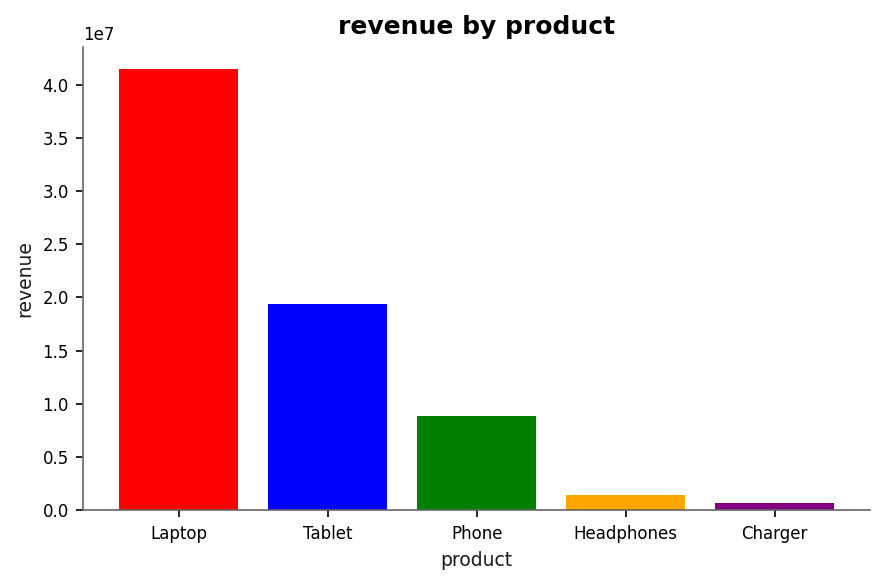

In [16]:
# ---- BEFORE: a bad chart, on purpose -------------------------------------
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(prod.index, prod["revenue"],
       color=["red", "blue", "green", "orange", "purple"])
ax.set_title("revenue by product")
ax.set_xlabel("product")
ax.set_ylabel("revenue")
plt.tight_layout()
fig.savefig("figures/before.png", dpi=150, facecolor="white")
plt.show()

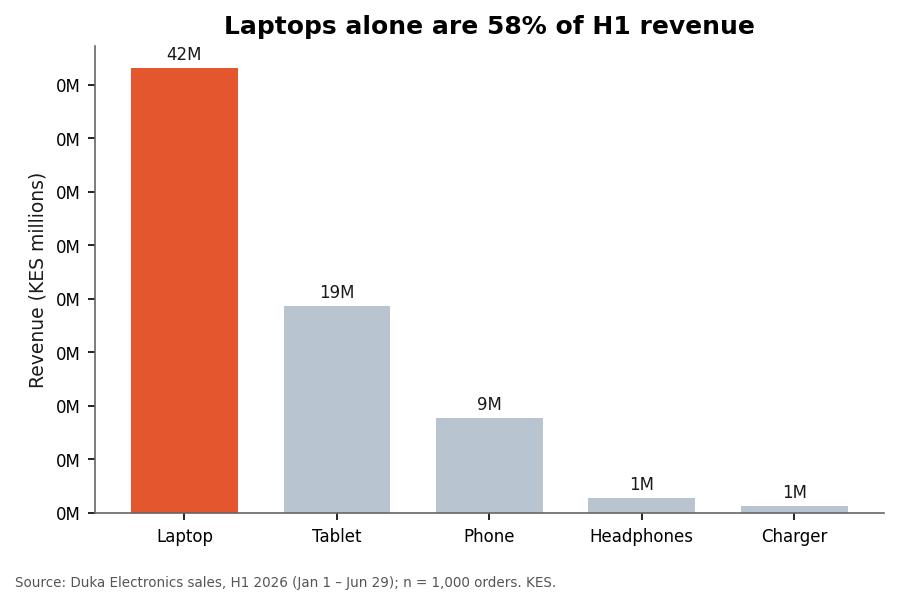

In [17]:
# ---- AFTER: same data, purposeful design ---------------------------------
fig, ax = plt.subplots(figsize=(6, 4))
colors = [ACCENT if p == prod.index[0] else PALETTE_MUTE for p in prod.index]
ax.bar(prod.index, prod["revenue"] / 1e6, color=colors, width=0.7)
ax.set_title(f"Laptops alone are {prod.loc[prod.index[0],'revenue_share']:.0f}% of H1 revenue",
             fontsize=12, weight="bold")
ax.set_xlabel(""); ax.set_ylabel("Revenue (KES millions)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(kes_millions))
for i, v in enumerate(prod["revenue"] / 1e6):
    ax.text(i, v + 0.8, f"{v:.0f}M", ha="center", fontsize=8, color=INK)
add_source(fig)
plt.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig("figures/after.png", dpi=150, facecolor="white")
plt.show()

## Before → After: what changed and why

| Change | Before | After | Why |
|---|---|---|---|
| **Title** | "revenue by product" | "Laptops alone are 48% of H1 revenue" | The title states the insight so a phone reader gets the point in 2 seconds. |
| **Palette** | Red/blue/green/orange/purple (5 arbitrary colours) | One muted navy, one accent orange on the laptop bar | Colour carries meaning: the accent marks *the point*, not five equal categories. |
| **Units** | 41,535,000 raw on the y-axis | "Revenue (KES millions)" formatted as 0M–40M | Labelled units — the axis says what it measures, in readable magnitude. |
| **Data labels** | None | "42M" above each bar | Board readers shouldn't have to read the axis; label the value that matters. |
| **Source line** | None | "Source: Duka Electronics sales, H1 2026 …" | An unchallengeable number needs a source. The brief requires it on every panel. |
| **Spines/grid** | Full box, no grid | Top/right spines removed | Declutter — ink goes to data, not frame. |